In [1]:
# CUSTOMER CHURN PREDICTION USING AN ARTIFICIAL NEURAL NETWORK (ANN)
# ACS Work Integrated Learning - Data Analytics | Team 3
# Prepared by: Zannatul Ferdous (Annie) | Role: Data Analyst - Predictive Modelling
# Data: team-approved processed dataset Version 2 (duplicates removed, stratified train/test split)

# STEP 1: LOAD THE LIBRARIES
# Purpose: Import the Python tools used for data handling, modelling, evaluation and charts.
# Reason: pandas handles tables, matplotlib draws charts and scikit-learn provides the models
# and scoring tools, so we do not need to write the maths from scratch.

import os, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, classification_report)
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)  # expected when training one epoch at a time
SEED = 42  # fixed random seed so results are the same every time
np.random.seed(SEED)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
print("Libraries loaded")

Libraries loaded


In [2]:
# STEP 2: LOAD THE PROCESSED DATASET (VERSION 2)
# Purpose: Load the training and test files prepared by the Data Engineers.
# Reason: The data is already cleaned, encoded and scaled, so it is ready for modelling.
# The training set is used to learn; the test set is kept hidden until the final evaluation.
# Upload the 4 v2 CSV files to Colab's Files panel before running.
# Expected: 5,392 training customers, 1,349 test customers, 10 features.

FILES = ["X_train_scaled_v2.csv", "X_test_scaled_v2.csv", "y_train_v2.csv", "y_test_v2.csv"]
candidates = ["../Data_Preparation/Final_Files_Both_version", "../data/processed", "data/processed", "."]
DATA_DIR = next((d for d in candidates if all(os.path.exists(os.path.join(d, f)) for f in FILES)), None)
if DATA_DIR is None:
    raise FileNotFoundError("Couldn't find the 4 v2 CSV files. Upload them to Colab's Files panel.")

X_train_full = pd.read_csv(os.path.join(DATA_DIR, "X_train_scaled_v2.csv"))
X_test       = pd.read_csv(os.path.join(DATA_DIR, "X_test_scaled_v2.csv"))
y_train_full = pd.read_csv(os.path.join(DATA_DIR, "y_train_v2.csv"))["Churn"]
y_test       = pd.read_csv(os.path.join(DATA_DIR, "y_test_v2.csv"))["Churn"]

print("Training customers:", X_train_full.shape[0], "| Test customers:", X_test.shape[0], "| Features:", X_train_full.shape[1])
print("Missing values:", int(X_train_full.isna().sum().sum() + X_test.isna().sum().sum()))
print(f"Churn rate - train: {y_train_full.mean():.1%}, test: {y_test.mean():.1%}")
X_train_full.head()

Training customers: 5392 | Test customers: 1349 | Features: 10
Missing values: 0
Churn rate - train: 26.6%, test: 26.5%


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,InternetService_Fiber optic,Contract_One year,Contract_Two year
0,0,-0.450593,1,0.944773,1,1,1.486201,1,0,0
1,0,-0.450593,0,1.232687,1,0,-0.234838,0,0,0
2,0,-0.450593,0,0.821382,1,0,0.946267,0,1,0
3,1,-0.450593,1,1.602861,1,0,1.621184,0,0,0
4,1,-0.450593,0,-0.988360,1,0,0.338842,0,0,0


In [3]:
# STEP 3: SET ASIDE A VALIDATION SET
# Purpose: Split 20% of the training customers into a validation set.
# Reason: We need somewhere to make decisions (when to stop training, which cut-off to use)
# without looking at the test set, otherwise the final score would be too optimistic.
# Training = homework, validation = practice exam, test = the real exam.
# stratify keeps the same churn rate in both parts.

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=SEED, stratify=y_train_full)
print("Learn from:", len(X_tr), "| Validation:", len(X_val), "| Test:", len(X_test))

Learn from: 4313 | Validation: 1079 | Test: 1349


In [4]:
# STEP 4: CREATE A BENCHMARK ("ALWAYS NO CHURN")
# Purpose: Score a lazy model that predicts every customer will stay.
# Reason: Only about 26% of customers churn, so this model looks accurate while catching
# zero churners. This shows why accuracy alone is misleading and why we also use recall.

lazy_pred = np.zeros(len(y_test), dtype=int)
print(f"'Always No' accuracy: {accuracy_score(y_test, lazy_pred):.1%}")
print(f"'Always No' churners caught (recall): {recall_score(y_test, lazy_pred):.1%}")

'Always No' accuracy: 73.5%
'Always No' churners caught (recall): 0.0%


In [5]:
# STEP 5: TRAIN A BASELINE MODEL (LOGISTIC REGRESSION)
# Purpose: Train a simple, well-known model that adds up weighted features to give a churn probability.
# Reason: It gives a fair comparison. If the more complex ANN cannot beat it, we report that honestly.
# class_weight="balanced" makes the model pay extra attention to churners, the smaller group.

logreg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
logreg.fit(X_tr, y_tr)
print("Logistic regression trained")

Logistic regression trained


In [6]:
# STEP 6: BUILD AND TRAIN THE ANN
# Purpose: Train a neural network to estimate each customer's probability of churning.
# Reason: An ANN can learn combinations of features (e.g. short tenure AND high charges)
# that a simple additive model may miss.
# How it works: 10 input features -> hidden layer of 16 neurons -> hidden layer of 8 neurons
# -> 1 output (probability of churn). ReLU activation; alpha=0.001 is a small penalty that
# discourages memorising. One epoch = one full pass over the training data.
# Early stopping: after every epoch we check the validation loss and keep the best version;
# training stops if it has not improved for 15 epochs. This prevents overfitting.

ann = MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu", alpha=0.001,
                    learning_rate_init=0.001, batch_size=64,
                    max_iter=1, warm_start=True, random_state=SEED)

train_loss, val_loss = [], []
best_loss, best_model, patience, wait = np.inf, None, 15, 0

for epoch in range(1, 201):
    ann.fit(X_tr, y_tr)  # one more epoch of learning
    train_loss.append(log_loss(y_tr, ann.predict_proba(X_tr)[:, 1]))
    val_loss.append(log_loss(y_val, ann.predict_proba(X_val)[:, 1]))
    if val_loss[-1] < best_loss - 1e-4:
        best_loss, best_model, best_epoch, wait = val_loss[-1], copy.deepcopy(ann), epoch, 0
    else:
        wait += 1
        if wait >= patience:
            break

ann = best_model
print(f"Trained for {epoch} epochs; best validation loss at epoch {best_epoch} ({best_loss:.4f})")

Trained for 77 epochs; best validation loss at epoch 62 (0.4552)


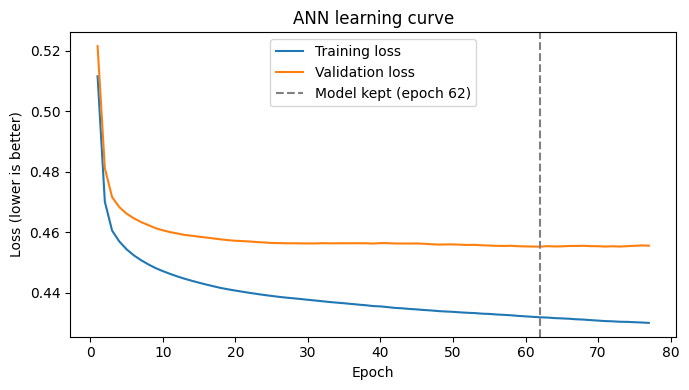

In [7]:
# STEP 7: PLOT THE LEARNING CURVE
# Purpose: Show the training and validation loss (how wrong the model is) after each epoch.
# Reason: Check for overfitting. If the training loss keeps falling while the validation
# loss rises, the model is memorising. The dashed line marks the version we kept.

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(train_loss) + 1), train_loss, label="Training loss")
plt.plot(range(1, len(val_loss) + 1), val_loss, label="Validation loss")
plt.axvline(best_epoch, linestyle="--", color="grey", label=f"Model kept (epoch {best_epoch})")
plt.xlabel("Epoch"); plt.ylabel("Loss (lower is better)")
plt.title("ANN learning curve"); plt.legend(); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/ann_learning_curve.png", dpi=150); plt.show()

**Interpretation:** For the first 5 epochs, both the training and validation loss dropped quickly. After that, the validation loss stayed slightly above the training loss, but the gap stayed about the same, which shows the model was learning general patterns. The validation loss stopped improving around epoch 62, so early stopping kept that version of the model.

In [8]:
# STEP 8: CHOOSE THE DECISION CUT-OFF (THRESHOLD)
# Purpose: Pick the probability above which a customer is flagged as "will churn".
# Reason: Churners are the minority, so the default 0.5 can miss many of them. Missing a
# churner usually costs more than a false alarm. We pick the cut-off with the best F1 score
# (balance of catching churners and avoiding false alarms) on the validation set, never the test set.

def best_threshold(model, X, y):
    probs = model.predict_proba(X)[:, 1]
    grid = np.arange(0.10, 0.91, 0.01)
    scores = [f1_score(y, (probs >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(scores))])

thr = {"Logistic Regression": best_threshold(logreg, X_val, y_val),
       "ANN": best_threshold(ann, X_val, y_val)}
print("Chosen cut-offs (from validation set):", {k: round(v, 2) for k, v in thr.items()})

Chosen cut-offs (from validation set): {'Logistic Regression': 0.46, 'ANN': 0.26}


In [9]:
# STEP 9: EVALUATE ON THE TEST SET
# Purpose: Compare the benchmark, logistic regression and the ANN on customers they have never seen.
# Reason: Evaluate beyond accuracy. Precision = of those flagged, how many really churned;
# Recall = of real churners, how many we caught (most important for retention);
# F1 = balance of precision and recall; ROC-AUC = how well risky customers are ranked
# above safe ones (0.5 = guessing, 1.0 = perfect).

models = {"Logistic Regression": logreg, "ANN": ann}
rows, preds, probs = [], {}, {}
rows.append({"Model": "Always 'No' (benchmark)", "Accuracy": accuracy_score(y_test, lazy_pred),
             "Precision": 0.0, "Recall": 0.0, "F1": 0.0, "ROC-AUC": 0.5, "Cut-off": "-"})
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]; probs[name] = p
    yhat = (p >= thr[name]).astype(int); preds[name] = yhat
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, yhat),
                 "Precision": precision_score(y_test, yhat), "Recall": recall_score(y_test, yhat),
                 "F1": f1_score(y_test, yhat), "ROC-AUC": roc_auc_score(y_test, p),
                 "Cut-off": round(thr[name], 2)})
results = pd.DataFrame(rows).set_index("Model")
results.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,Cut-off
Model,,,,,,
Always 'No' (benchmark),0.735,0.000,0.000,0.000,0.500,-
Logistic Regression,0.719,0.482,0.799,0.601,0.817,0.46
ANN,0.742,0.510,0.749,0.606,0.810,0.26


**Interpretation:** Both models performed much better than the 'always No' benchmark, which caught 0% of churners, while the ANN caught 75% (recall). The ANN and logistic regression scored almost the same, with F1 of 0.606 and 0.601 and ROC-AUC of 0.810 and 0.817 respectively. Using a lower cut-off of 0.26 helped the ANN catch more churners, at the cost of more false alarms. This suggests that with only 10 features, a simple model can capture most of the churn patterns.

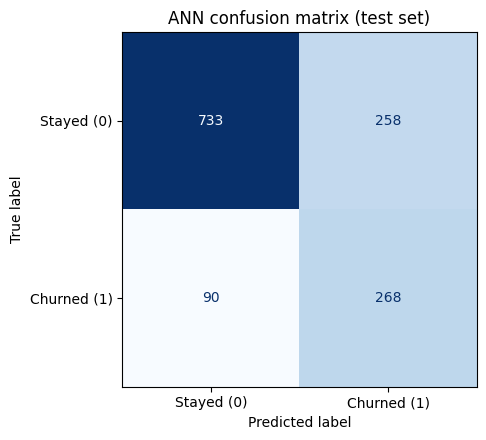

              precision    recall  f1-score   support

      Stayed       0.89      0.74      0.81       991
     Churned       0.51      0.75      0.61       358

    accuracy                           0.74      1349
   macro avg       0.70      0.74      0.71      1349
weighted avg       0.79      0.74      0.75      1349



In [10]:
# STEP 10: CONFUSION MATRIX
# Purpose: Show the ANN's test predictions as a 2x2 table of customers.
# Reason: Turns percentages into numbers of people.
# Top-left = stayed, predicted stay (correct); bottom-right = churned, predicted churn (caught);
# top-right = false alarm; bottom-left = missed churner (the costly mistake).

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, preds["ANN"]),
                       display_labels=["Stayed (0)", "Churned (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("ANN confusion matrix (test set)"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/ann_confusion_matrix.png", dpi=150); plt.show()
print(classification_report(y_test, preds["ANN"], target_names=["Stayed", "Churned"]))

**Interpretation:** Out of 358 customers who actually churned, the ANN correctly caught 268 but missed 90. It also flagged 258 customers who would have stayed (false alarms). For the retention team, this means about half of the customers they contact would be real churners, while only 90 churners would leave without being contacted.

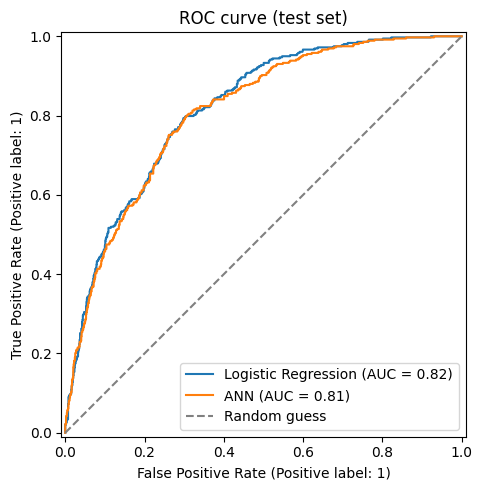

In [11]:
# STEP 11: ROC CURVE
# Purpose: Show how well each model separates churners from non-churners at every possible cut-off.
# Reason: The closer the curve is to the top-left corner, the better. The diagonal dashed
# line is random guessing. AUC is the area under the curve.

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
ax.set_title("ROC curve (test set)"); ax.legend(); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/roc_curve.png", dpi=150); plt.show()

**Interpretation:** Both curves sit well above the diagonal line, which shows the models are much better than random guessing. The two curves are close together, with AUC of about 0.81 for the ANN and 0.82 for logistic regression. This means the ANN can correctly rank a churner above a non-churner about 81% of the time.

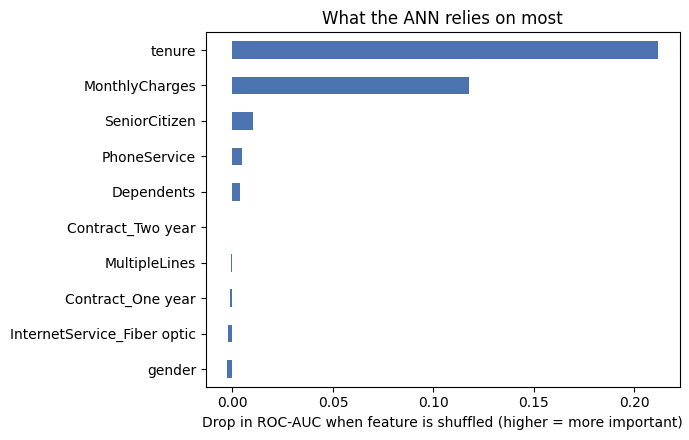

,0
tenure,0.2120
MonthlyCharges,0.1177
SeniorCitizen,0.0101
PhoneService,0.0047
Dependents,0.0035
Contract_Two year,-0.0002
MultipleLines,-0.0007
Contract_One year,-0.0011
InternetService_Fiber optic,-0.0024
gender,-0.0026


In [12]:
# STEP 12: FEATURE IMPORTANCE (WHAT DRIVES CHURN)
# Purpose: Measure how much the ANN relies on each feature using permutation importance.
# Reason: ANNs are hard to explain ("black box"). Shuffling one feature at a time and measuring
# the drop in ROC-AUC shows which customer details matter most, which links the model to
# practical retention recommendations.

imp = permutation_importance(ann, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(7, 4.5))
importance.plot(kind="barh", color="#4C72B0")
plt.xlabel("Drop in ROC-AUC when feature is shuffled (higher = more important)")
plt.title("What the ANN relies on most"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/ann_feature_importance.png", dpi=150); plt.show()
importance.sort_values(ascending=False).round(4)

**Interpretation:** The ANN relies most on tenure and monthly charges, while features such as one-year contract and fibre optic internet have almost no effect. This matches the data, where new customers churned at 48% compared with 9.6% for long-term customers. To reduce churn, the company could focus on new customers, for example through an onboarding programme in their first 12 months and loyalty discounts.

In [13]:
# STEP 13: EXPORT RESULTS
# Purpose: Save the ANN's test-set predictions and the result charts.
# Reason: Preserve the results for review, sharing with the project team and use in the final report.
# Each row is one test customer: actual churn, the ANN's churn probability and its prediction.

predictions = X_test.copy()
predictions["Actual_Churn"] = y_test.values
predictions["ANN_Churn_Probability"] = probs["ANN"].round(4)
predictions["ANN_Predicted_Churn"] = preds["ANN"]
predictions.to_csv("ANN_Churn_Predictions.csv", index=False)
print("Saved ANN_Churn_Predictions.csv and charts in the figures folder:", sorted(os.listdir(FIG_DIR)))

try:
    from google.colab import files  # only works in Google Colab
    files.download("ANN_Churn_Predictions.csv")
    for f in sorted(os.listdir(FIG_DIR)):
        files.download(os.path.join(FIG_DIR, f))
except ImportError:
    pass

Saved ANN_Churn_Predictions.csv and charts in the figures folder: ['ann_confusion_matrix.png', 'ann_feature_importance.png', 'ann_learning_curve.png', 'roc_curve.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Summary**

**Why an ANN:** it can learn combinations of features (e.g. short tenure *and* high charges) that a simple additive model may miss. We compared it against logistic regression to check whether the extra complexity is worth it.

**Results (test set):** On the test set, the ANN caught 75% of churners (recall), with an F1 score of 0.606 and ROC-AUC of 0.810. Logistic regression scored very similarly (recall 80%, F1 0.601, ROC-AUC 0.817). Both models clearly beat the 'always No' benchmark, which caught 0% of churners. Because the ANN did not clearly outperform the simpler model, the team could choose either model, and the ANN's main value is confirming which features drive churn.

**Limitations:**
- Only 10 features, so the model can only learn from limited information about each customer
- Some customers have identical details but different churn outcomes, so no model can predict them all correctly
- ANNs are harder to explain than simple models; permutation importance helps but is only a partial explanation
- The chosen cut-off balances catching churners vs false alarms; the business may prefer a different balance

**Possible improvements:** more customer data (e.g. usage, complaints, payment method), trying other models (e.g. random forest), and tuning the network size.